In [4]:
#Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical


In [5]:
#Loading Data Set
data = pd.read_csv("features.csv")
print("Dataset shape:", data.shape)
data.head()


Dataset shape: (10299, 68)


,0,1,2,3,4,5,6,7,8,9,...,58,59,60,61,62,63,64,65,Activity,Subject
0,0.002269,0.002941,-0.004294,0.010810,0.481111,-0.395797,-0.001655,0.004601,-0.012610,0.010767,...,0.000014,0.000024,0.000408,0.000703,0.000770,0.000125,0.000446,0.001598,STANDING,1
1,0.000174,0.001981,-0.006706,0.005251,-0.480776,1.472747,0.000382,0.005930,-0.012610,0.016634,...,0.000004,0.000035,0.000128,0.000409,0.000126,0.000095,0.000167,0.000630,STANDING,1
2,0.000428,0.002908,-0.010483,0.008167,-0.565241,1.802622,-0.001222,0.007310,-0.015333,0.016634,...,0.000009,0.000055,0.000049,0.000513,0.000208,0.000095,0.000113,0.000816,STANDING,1
3,0.000329,0.002678,-0.010483,0.008167,-0.343696,2.627266,-0.004753,0.004551,-0.015333,0.005359,...,0.000007,0.000043,0.000046,0.000347,0.000120,0.000067,0.000097,0.000534,STANDING,1
4,-0.000195,0.002015,-0.006847,0.005650,-0.139971,0.577671,0.000298,0.004991,-0.014662,0.009661,...,0.000004,0.000025,0.000028,0.000254,0.000061,0.000084,0.000057,0.000399,STANDING,1


In [6]:
# Separating Features and Labels
X = data.drop(columns=["Activity", "Subject"])
y = data["Activity"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
y_onehot = to_categorical(y_encoded)

print("Classes:", label_encoder.classes_)


Classes: ['LAYING' 'SITTING' 'STANDING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']


In [9]:
# Training and validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y_onehot, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_onehot
)


In [10]:
# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)


In [11]:
# Building FCNN Model
from tensorflow.keras.layers import Input

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))

model.add(Dense(128, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(6, activation='softmax'))

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,110 (74.65 KB)

 Trainable params: 19,110 (74.65 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Training the Model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)


Epoch 1/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5997 - loss: 0.8754 - val_accuracy: 0.6650 - val_loss: 0.7095
Epoch 2/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6973 - loss: 0.6545 - val_accuracy: 0.6913 - val_loss: 0.6519
Epoch 3/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7202 - loss: 0.5967 - val_accuracy: 0.6786 - val_loss: 0.6661
Epoch 4/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7428 - loss: 0.5533 - val_accuracy: 0.7500 - val_loss: 0.5656
Epoch 5/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7662 - loss: 0.5090 - val_accuracy: 0.7248 - val_loss: 0.5988
Epoch 6/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7825 - loss: 0.4740 - val_accuracy: 0.7718 - val_loss: 0.5224
Epoch 7/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8013 - loss: 0.4411 - val_accuracy: 0.7646 - val_loss: 0.5307
Epoch 8/30
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8088 - loss: 0.4282 - val_accuracy: 0.

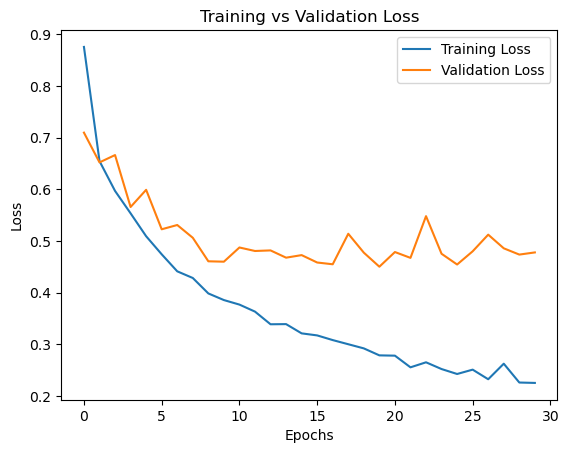

In [13]:
# Plot Training vs Validation Loss
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Training Loss", "Validation Loss"])
plt.title("Training vs Validation Loss")
plt.show()


In [14]:
# Model Evaluation
y_pred_probs = model.predict(X_val)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_val, axis=1)

accuracy = accuracy_score(y_true, y_pred)
print("Validation Accuracy:", accuracy)


65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step  
Validation Accuracy: 0.8427184466019417


In [15]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[283  53  51   0   0   2]
 [ 34 262  60   0   0   0]
 [ 27  62 292   0   0   0]
 [  0   0   0 325   1  18]
 [  0   0   0   4 271   6]
 [  0   0   0   2   4 303]]


In [16]:
#Classification Report
print(classification_report(
    y_true, 
    y_pred, 
    target_names=label_encoder.classes_
))


                    precision    recall  f1-score   support

            LAYING       0.82      0.73      0.77       389
           SITTING       0.69      0.74      0.71       356
          STANDING       0.72      0.77      0.74       381
           WALKING       0.98      0.94      0.96       344
WALKING_DOWNSTAIRS       0.98      0.96      0.97       281
  WALKING_UPSTAIRS       0.92      0.98      0.95       309

          accuracy                           0.84      2060
         macro avg       0.85      0.85      0.85      2060
      weighted avg       0.85      0.84      0.84      2060



In [17]:
# Saving the model
model.save("fcnn_model.keras")
print("Model saved as fcnn_model.keras")

Model saved as fcnn_model.keras
